# Assessment 6: Time Series Analysis (AirPassengers) | BCSE331P - Exploratory Data Analysis | Fall Semester 2026-27

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

plt.rcParams["figure.figsize"] = (10, 5)

## 1. Load the AirPassengers dataset


In [2]:
ap_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,   # 1949
    115,126,141,135,125,149,170,170,158,133,114,140,   # 1950
    145,150,178,163,172,178,199,199,184,162,146,166,   # 1951
    171,180,193,181,183,218,230,242,209,191,172,194,   # 1952
    196,196,236,235,229,243,264,272,237,211,180,201,   # 1953
    204,188,235,227,234,264,302,293,259,229,203,229,   # 1954
    242,233,267,269,270,315,364,347,312,274,237,278,   # 1955
    284,277,317,313,318,374,413,405,355,306,271,306,   # 1956
    315,301,356,348,355,422,465,467,404,347,305,336,   # 1957
    340,318,362,348,363,435,491,505,404,359,310,337,   # 1958
    360,342,406,396,420,472,548,559,463,407,362,405,   # 1959
    417,391,419,461,472,535,622,606,508,461,390,432    # 1960
]
idx = pd.date_range(start="1949-01-01", periods=len(ap_values), freq="MS")
AirPassengers = pd.Series(ap_values, index=idx, name="AirPassengers")
print("Observations:", len(AirPassengers))

Observations: 144


## 2. First five and last five observations

In [3]:
print("First 5:")
display(AirPassengers.head(5))
print("Last 5:")
display(AirPassengers.tail(5))

First 5:


,AirPassengers
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


Last 5:


,AirPassengers
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


## 3. Start and end time periods

In [4]:
start, end = AirPassengers.index[0], AirPassengers.index[-1]
print(f"Start: year {start.year}, month {start.month}  ({start.strftime('%b %Y')})")
print(f"End  : year {end.year}, month {end.month}  ({end.strftime('%b %Y')})")

Start: year 1949, month 1  (Jan 1949)
End  : year 1960, month 12  (Dec 1960)


## 4. Frequency and time-series characteristics

In [5]:
print("Class of object :", type(AirPassengers))
print("Index type      :", type(AirPassengers.index).__name__)
print("Inferred freq   :", AirPassengers.index.freqstr, "(Month Start)  -> 12 observations per year")
print("Frequency (R)   : 12")
print("Years covered   :", end.year - start.year + 1)
print()
display(AirPassengers.describe().round(2))

Class of object : <class 'pandas.core.series.Series'>
Index type      : DatetimeIndex
Inferred freq   : MS (Month Start)  -> 12 observations per year
Frequency (R)   : 12
Years covered   : 12



,AirPassengers
count,144.00
mean,280.30
std,119.97
min,104.00
25%,180.00
50%,265.50
75%,360.50
max,622.00


## 5. Monthly passenger trend

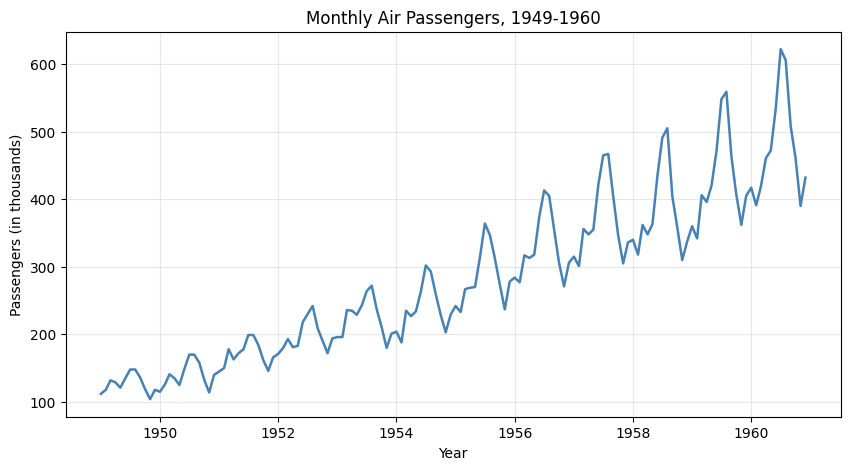

In [6]:
fig, ax = plt.subplots()
ax.plot(AirPassengers, color="steelblue", linewidth=1.8)
ax.set_title("Monthly Air Passengers, 1949-1960")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (in thousands)")
ax.grid(alpha=0.3)
plt.show()

## 6. Decompose into trend, seasonal and random components

In [7]:
decomp = seasonal_decompose(AirPassengers, model="additive", period=12)

print("Seasonal figures (one value per month):")
display(decomp.seasonal.head(12).round(2).to_frame("seasonal"))
display(pd.DataFrame({"observed": decomp.observed, "trend": decomp.trend,
                      "seasonal": decomp.seasonal, "random": decomp.resid}).head(12).round(2))

Seasonal figures (one value per month):


,seasonal
1949-01-01,-24.75
1949-02-01,-36.19
1949-03-01,-2.24
1949-04-01,-8.04
1949-05-01,-4.51
1949-06-01,35.40
1949-07-01,63.83
1949-08-01,62.82
1949-09-01,16.52
1949-10-01,-20.64


,observed,trend,seasonal,random
1949-01-01,112.0,NaN,-24.75,NaN
1949-02-01,118.0,NaN,-36.19,NaN
1949-03-01,132.0,NaN,-2.24,NaN
1949-04-01,129.0,NaN,-8.04,NaN
1949-05-01,121.0,NaN,-4.51,NaN
1949-06-01,135.0,NaN,35.40,NaN
1949-07-01,148.0,126.79,63.83,-42.62
1949-08-01,148.0,127.25,62.82,-42.07
1949-09-01,136.0,127.96,16.52,-8.48
1949-10-01,119.0,128.58,-20.64,11.06


## 7. Plot the decomposed components

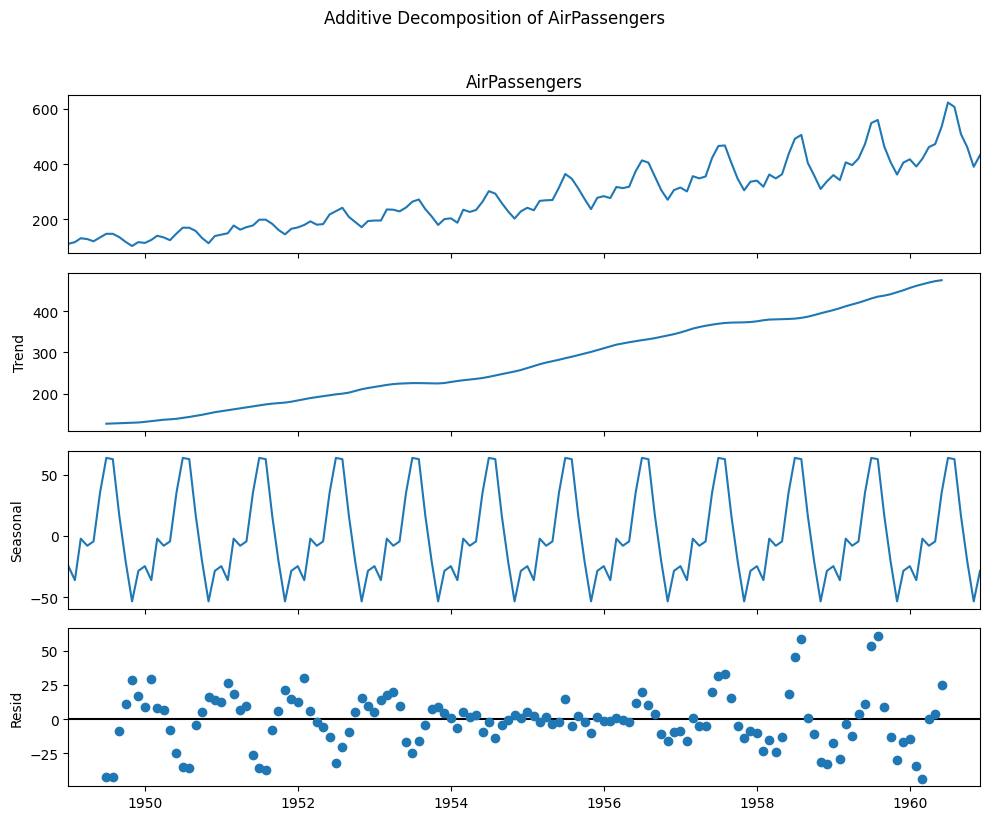

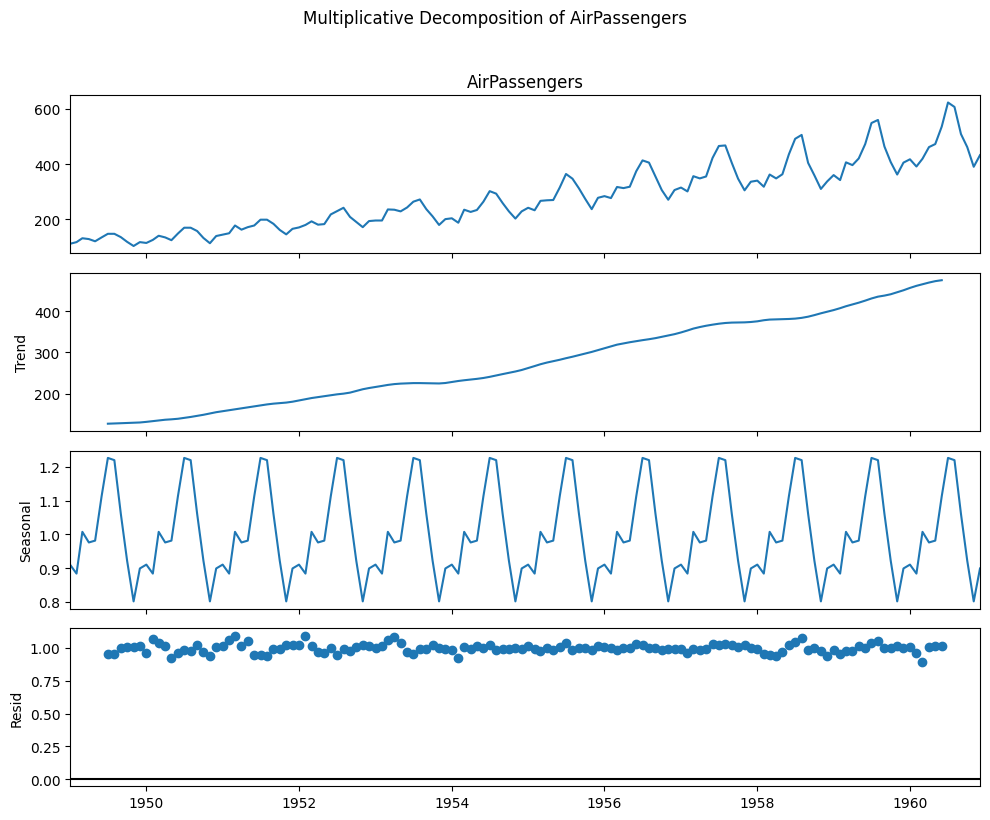

In [8]:
fig = decomp.plot()
fig.set_size_inches(10, 8)
fig.suptitle("Additive Decomposition of AirPassengers", y=1.02)
plt.tight_layout()
plt.show()

# optional: multiplicative decomposition fits this series better (random part is more stable)
decomp_mul = seasonal_decompose(AirPassengers, model="multiplicative", period=12)
fig = decomp_mul.plot()
fig.set_size_inches(10, 8)
fig.suptitle("Multiplicative Decomposition of AirPassengers", y=1.02)
plt.tight_layout()
plt.show()

## 8. Autocorrelation (ACF) and partial autocorrelation (PACF)

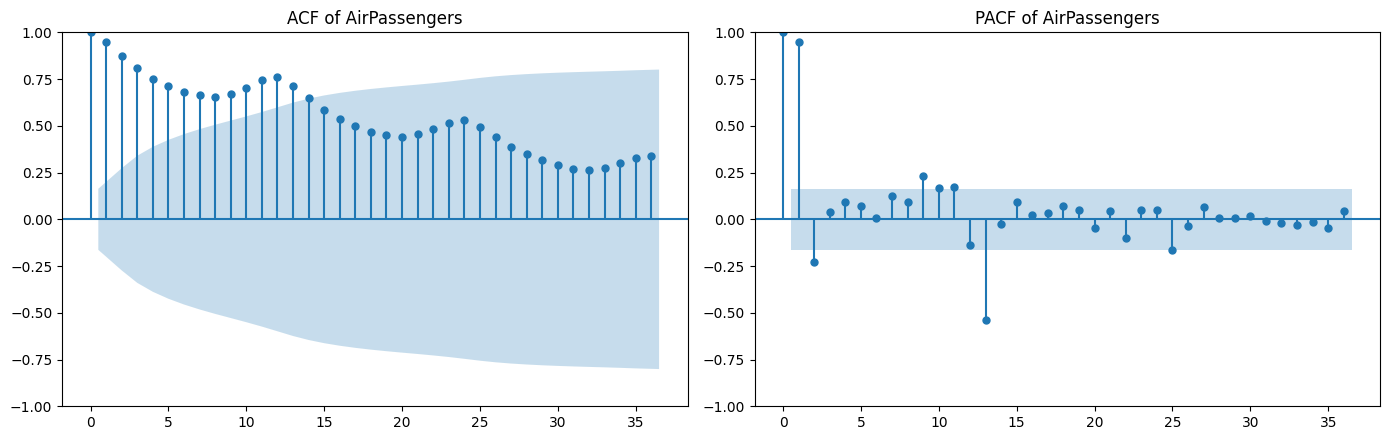

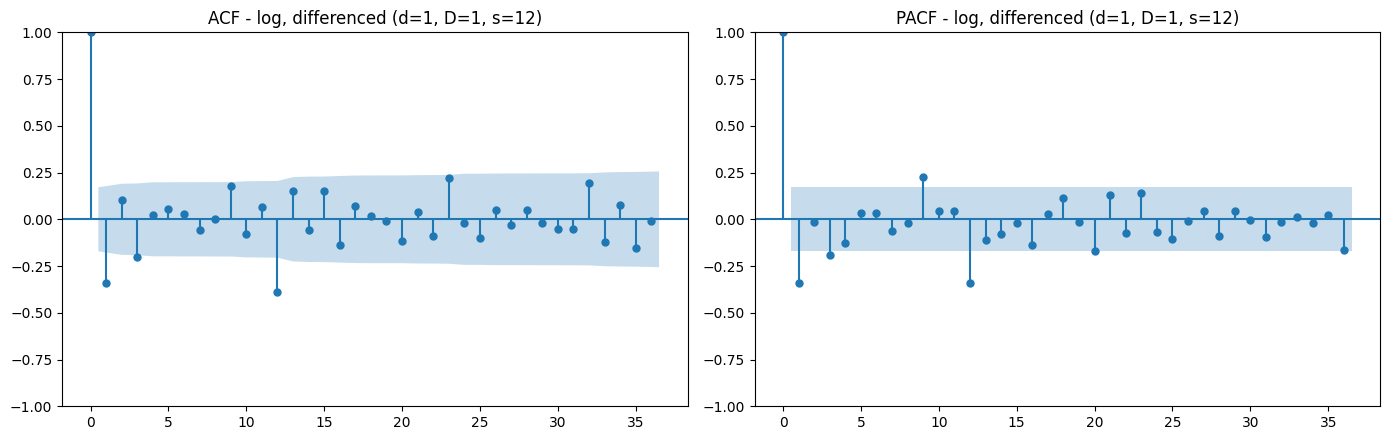

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_acf(AirPassengers, lags=36, ax=axes[0])
axes[0].set_title("ACF of AirPassengers")
plot_pacf(AirPassengers, lags=36, ax=axes[1], method="ywm")
axes[1].set_title("PACF of AirPassengers")
plt.tight_layout()
plt.show()

# on the differenced (stationary) log series
log_ap = np.log(AirPassengers)
diff_ap = log_ap.diff().diff(12).dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_acf(diff_ap, lags=36, ax=axes[0]);  axes[0].set_title("ACF - log, differenced (d=1, D=1, s=12)")
plot_pacf(diff_ap, lags=36, ax=axes[1], method="ywm"); axes[1].set_title("PACF - log, differenced (d=1, D=1, s=12)")
plt.tight_layout()
plt.show()

## 9. Fit an ARIMA model


In [10]:
candidates = [
    ((1, 1, 0), (0, 1, 0, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),     # airline model
    ((1, 1, 1), (0, 1, 1, 12)),
    ((2, 1, 1), (0, 1, 1, 12)),
]
results = []
for order, sorder in candidates:
    m = ARIMA(log_ap, order=order, seasonal_order=sorder).fit()
    results.append({"order": order, "seasonal_order": sorder, "AIC": round(m.aic, 2), "BIC": round(m.bic, 2)})
comp = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
display(comp)

best = comp.iloc[0]
best_order, best_sorder = best["order"], best["seasonal_order"]
print("Selected model: ARIMA", best_order, "x", best_sorder)

model = ARIMA(log_ap, order=best_order, seasonal_order=best_sorder).fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,order,seasonal_order,AIC,BIC
0,"(0, 1, 1)","(0, 1, 1, 12)",-483.39,-474.77
1,"(2, 1, 1)","(0, 1, 1, 12)",-482.25,-467.87
2,"(1, 1, 1)","(0, 1, 1, 12)",-481.89,-470.39
3,"(1, 1, 0)","(0, 1, 0, 12)",-449.01,-443.26


Selected model: ARIMA (0, 1, 1) x (0, 1, 1, 12)


## 10. Display and interpret the model parameters / summary

In [11]:
print(model.summary())

                                    SARIMAX Results                                     
Dep. Variable:                    AirPassengers   No. Observations:                  144
Model:             ARIMA(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 244.696
Date:                          Sat, 17 Oct 2026   AIC                           -483.393
Time:                                  13:32:51   BIC                           -474.767
Sample:                              01-01-1949   HQIC                          -479.888
                                   - 12-01-1960                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4017      0.073     -5.501      0.000      -0.545      -0.259
ma.S.L12      -0.5569      0.096     -5.783      0.

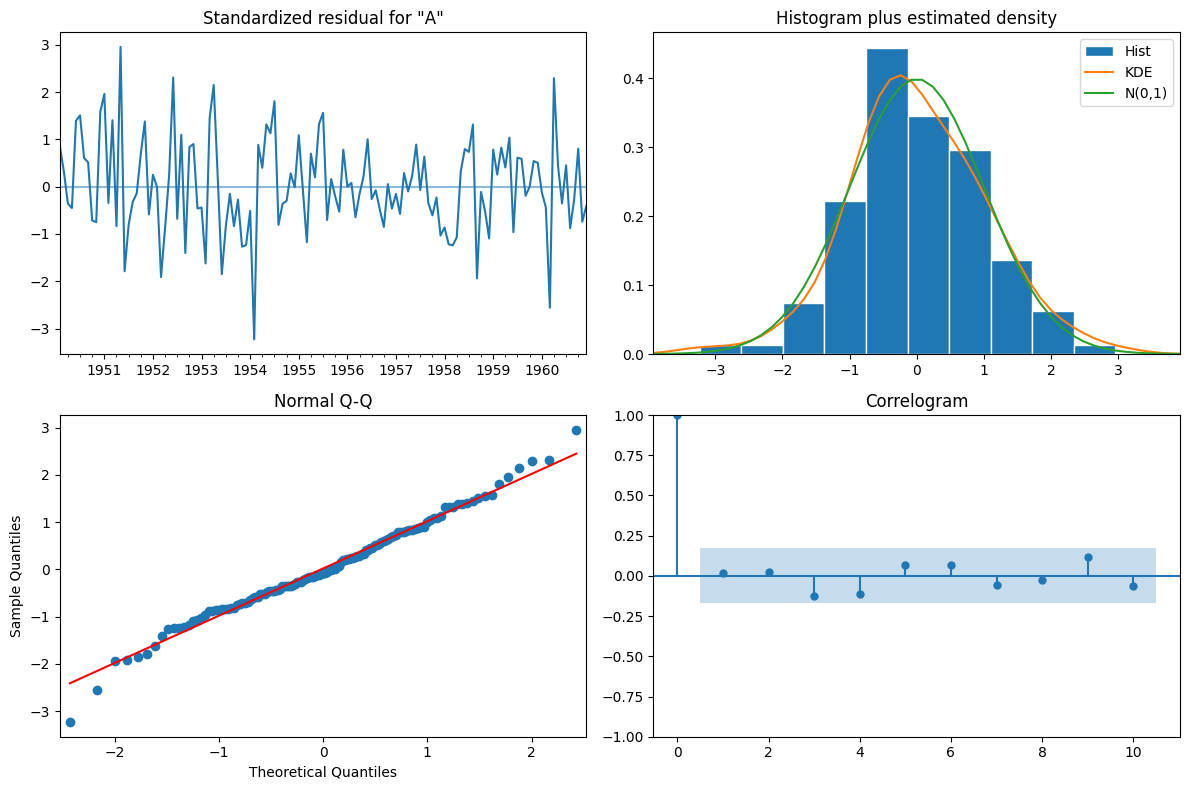

In [12]:
fig = model.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

## 11. Forecast the next 12 months

In [13]:
fc = model.get_forecast(steps=12)
fc_mean = np.exp(fc.predicted_mean)                  # back-transform from log scale
fc_ci = np.exp(fc.conf_int(alpha=0.05))
fc_ci.columns = ["lower_95", "upper_95"]

forecast_df = pd.concat([fc_mean.rename("forecast"), fc_ci], axis=1).round(1)
forecast_df.index = forecast_df.index.strftime("%b %Y")
display(forecast_df)

,forecast,lower_95,upper_95
Jan 1961,450.4,419.1,484.0
Feb 1961,425.7,391.5,463.0
Mar 1961,479.0,435.9,526.4
Apr 1961,492.4,443.9,546.2
May 1961,509.1,455.0,569.5
Jun 1961,583.3,517.3,657.8
Jul 1961,670.0,589.7,761.3
Aug 1961,667.1,583.0,763.3
Sep 1961,558.2,484.6,643.0
Oct 1961,497.2,428.9,576.4


## 12. Actual vs forecasted values

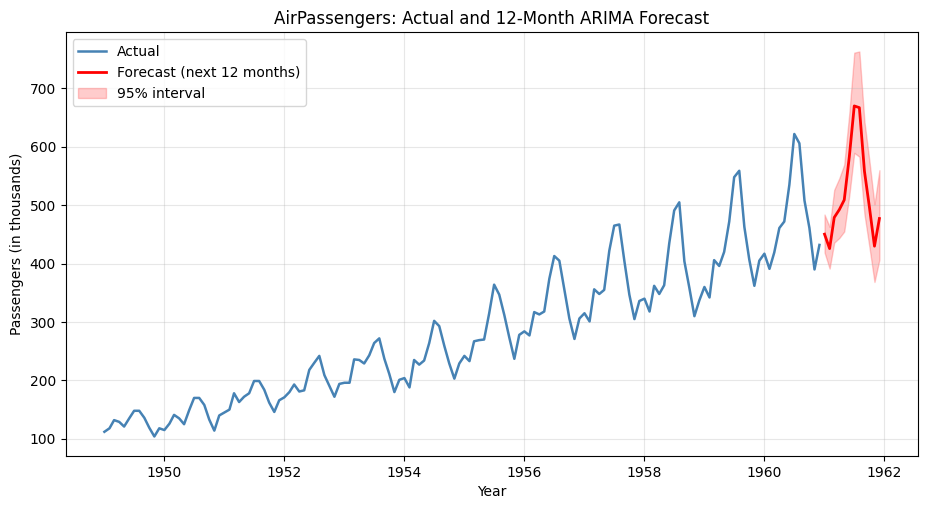

In [14]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(AirPassengers, label="Actual", color="steelblue", linewidth=1.8)
ax.plot(fc_mean, label="Forecast (next 12 months)", color="red", linewidth=2)
ax.fill_between(fc_ci.index, fc_ci["lower_95"], fc_ci["upper_95"], color="red", alpha=0.2, label="95% interval")
ax.set_title("AirPassengers: Actual and 12-Month ARIMA Forecast")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (in thousands)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()